# Satellite article figures

Satellite-only figures (funnel, conditions), numbers check, cover image.

Cells are the original session code in execution order (exported verbatim; only secrets handling and artifact paths were changed). Each cell starts with a comment giving its original index, conda environment and run status. Exploratory and failed cells are kept, so later cells that rely on their partial state still make sense.


In [ ]:
# Setup: run from the repository root; helper modules live in prod/
import os, sys
if os.path.basename(os.getcwd())=='notebooks': os.chdir('..')
sys.path.insert(0, 'prod')
os.makedirs('out', exist_ok=True)
from style import apply_figure_style  # stand-in for the figure style used in the session


In [186]:
# [orig cell 185 | env: python | status: ok]
import pandas as pd, numpy as np
DS=pd.read_csv('out/detection_scores.csv')
CS=pd.read_csv('out/conditional_scores.csv')
sat=['pccs','cmorph','imerg']; ref=['stage4']
d=DS[(DS['product'].isin(sat+ref))]
print(d[(d.threshold==30)].pivot_table(index='product',columns='nbhd',values=['hit_ge1','hit_ge10','hit_strict']).round(3).to_string())
print(d[d.nbhd=='N1'].pivot_table(index='product',columns='threshold',values='ratio_median').round(3))
print(d[d.nbhd=='N16'].pivot_table(index='product',columns='threshold',values='ratio_median').round(3))
c=CS[(CS.threshold==20)&(CS['product'].isin(sat+ref))]
for cond in ['storm_type','season','time_of_day']:
    print(cond); print(c[(c.nbhd=='N1')&(c.condition==cond)].pivot_table(index='level',columns='product',values='ratio_median').round(2))
    print(c[(c.nbhd=='N9')&(c.condition==cond)].pivot_table(index='level',columns='product',values=['hit_strict','hit_ge10']).round(2))
print(c[(c.nbhd=='N9')&(c.condition=='storm_type')&(c['product']=='imerg')][['level','n_events']])

        hit_ge1                      hit_ge10                      hit_strict                     
nbhd         N1    N16     N4     N9       N1    N16     N4     N9         N1    N16     N4     N9
product                                                                                           
cmorph    0.726  0.863  0.795  0.832    0.205  0.405  0.295  0.352      0.009  0.041  0.019  0.030
imerg     0.812  0.961  0.902  0.945    0.149  0.399  0.257  0.343      0.005  0.029  0.013  0.022
pccs      0.676  0.859  0.754  0.822    0.252  0.479  0.334  0.406      0.026  0.081  0.044  0.064
stage4    0.966  0.982  0.975  0.980    0.844  0.941  0.905  0.933      0.350  0.697  0.555  0.663
threshold     20     30     40     50
product                              
cmorph     0.094  0.091  0.086  0.076
imerg      0.119  0.099  0.092  0.082
pccs       0.095  0.099  0.096  0.100
stage4     0.642  0.623  0.603  0.589
threshold     20     30     40     50
product                              
cmo

In [187]:
# [orig cell 186 | env: python | status: ok]
import matplotlib as mpl, matplotlib.pyplot as plt
mpl.rcParams.update({'font.size':11,'font.family':'DejaVu Sans','axes.spines.top':False,'axes.spines.right':False})
nice={'stage4':'Stage IV radar\n(reference, 4 km)','pccs':'PERSIANN-CCS\n(infrared, 4 km)','cmorph':'CMORPH CDR\n(microwave+IR, 8 km)','imerg':'IMERG V07 Final\n(microwave+IR, 10 km)'}
col={'stage4':'#2171b5','pccs':'#fd8d3c','cmorph':'#e6550d','imerg':'#a63603'}
order=['imerg','cmorph','pccs','stage4']
t=DS[(DS.threshold==30)&(DS.nbhd=='N9')].set_index('product')
steps=[('hit_ge1','shows rain\n(≥1 mm/h)'),('hit_ge10','shows heavy rain\n(≥10 mm/h)'),('hit_strict','shows the extreme\n(≥30 mm/h)')]
fig,ax=plt.subplots(figsize=(11,5.4))
y=np.arange(len(order))*1.0; h=0.26
shades=[0.35,0.65,1.0]
for k,(c_,lab) in enumerate(steps):
    for i,p in enumerate(order):
        v=t.loc[p,c_]*100; yy=y[i]+(1-k)*h
        ax.barh(yy,v,h*0.9,color=col[p],alpha=shades[k])
        ax.text(v+1,yy,f'{v:.0f}%' if v>=1 else f'{v:.1f}%',va='center',fontsize=10)
        if i==0: ax.text(-1,yy,lab.replace('\n',' '),va='center',ha='right',fontsize=9.5,color='0.35')
ax.set_yticks(y); ax.set_yticklabels([nice[p] for p in order],fontsize=10.5)
ax.tick_params(axis='y',pad=150)
ax.set_xlim(0,108); ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(100))
ax.set_xlabel('% of 2,769 gauge-measured ≥30 mm/h events (3×3 pixels around each gauge)',fontsize=10.5)
ax.set_title('Satellites see the storm, but rarely the downpour',loc='left',fontsize=14,pad=10)
fig.savefig('sat_fig2_funnel.png',dpi=200,bbox_inches='tight')

Matplotlib is building the font cache; this may take a moment.

In [188]:
# [orig cell 187 | env: python | status: ok]
import matplotlib.patches as mpa
fig,ax=plt.subplots(figsize=(11,5.4))
for k,(c_,lab) in enumerate(steps):
    for i,p in enumerate(order):
        v=t.loc[p,c_]*100; yy=y[i]+(1-k)*h
        ax.barh(yy,v,h*0.9,color=col[p],alpha=shades[k])
        ax.text(v+1,yy,f'{v:.0f}%' if v>=1 else f'{v:.1f}%',va='center',fontsize=10)
ax.set_yticks(y); ax.set_yticklabels([nice[p] for p in order],fontsize=10.5)
ax.set_xlim(0,112); ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(100)); ax.set_xticks([0,20,40,60,80,100])
ax.set_xlabel('% of 2,769 gauge-measured ≥30 mm/h events (3×3 pixels around each gauge)',fontsize=10.5)
ax.set_title('Satellites see the storm, but rarely the downpour',loc='left',fontsize=14,pad=10)
hd=[mpa.Patch(color='0.3',alpha=a,label=l.replace('\n',' ')) for a,(_,l) in zip(shades,steps)]
ax.legend(handles=hd,frameon=False,fontsize=10,loc='lower right',title='bar (top to bottom) = product…',title_fontsize=9.5)
fig.savefig('sat_fig2_funnel.png',dpi=200,bbox_inches='tight')

In [189]:
# [orig cell 188 | env: python | status: ok]
ax.get_legend().remove()
ax.legend(handles=hd,frameon=False,fontsize=10,loc='lower left',bbox_to_anchor=(0,1.0),ncol=3,handlelength=1.6)
ax.set_title('Satellites see the storm, but rarely the downpour',loc='left',fontsize=14,pad=34)
fig.savefig('sat_fig2_funnel.png',dpi=200,bbox_inches='tight')
r=fig.canvas.get_renderer(); tx=[x for x in fig.findobj(mpl.text.Text) if x.get_text().strip() and x.get_visible()]; bb=[x.get_window_extent(r) for x in tx]
print([(tx[i].get_text()[:20],tx[j].get_text()[:20]) for i in range(len(bb)) for j in range(i+1,len(bb)) if bb[i].overlaps(bb[j])])

[('% of 2,769 gauge-mea', '20%'), ('% of 2,769 gauge-mea', '40%'), ('% of 2,769 gauge-mea', '60%'), ('% of 2,769 gauge-mea', '80%')]


In [190]:
# [orig cell 189 | env: python | status: ok]
c=CS[(CS.threshold==20)&(CS.nbhd=='N9')]
sats=['pccs','cmorph','imerg']; lab3={'pccs':'PERSIANN-CCS (infrared)','cmorph':'CMORPH (microwave+IR)','imerg':'IMERG (microwave+IR)'}
groups=[('storm_type',['Warm-season isolated convection','Warm-season organized (MCS-like)','Tropical cyclone','Cool-season (frontal)'],['Isolated summer\nthunderstorms','Organized\nsystems','Tropical\ncyclones','Cool-season\nfronts'],'By storm type'),
        ('time_of_day',['Night 00–06','Morning 06–12','Afternoon 12–18','Evening 18–24'],['Night\n00–06','Morning\n06–12','Afternoon\n12–18','Evening\n18–24'],'By local time of day')]
fig,axs=plt.subplots(1,2,figsize=(13,4.8),sharey=True,gridspec_kw=dict(wspace=0.06))
w=0.26
for ax,(cond,levels,labels,ttl) in zip(axs,groups):
    x=np.arange(len(levels))
    for i,p in enumerate(sats):
        vals=[c[(c.condition==cond)&(c.level==l)&(c['product']==p)].hit_strict.iloc[0]*100 for l in levels]
        ax.bar(x+(i-1)*w,vals,w*0.92,color=col[p],label=lab3[p])
        for xi,v in zip(x+(i-1)*w,vals): ax.text(xi,v+0.3,f'{v:.0f}%',ha='center',va='bottom',fontsize=9.5)
    n=[int(c[(c.condition==cond)&(c.level==l)&(c['product']=='imerg')].n_events.iloc[0]) for l in levels]
    ax.set_xticks(x); ax.set_xticklabels([f'{a}\n(n={b:,})' for a,b in zip(labels,n)],fontsize=10)
    ax.set_title(ttl,loc='left',fontsize=12)
axs[0].set_ylabel('% of ≥20 mm/h gauge events the\nsatellite also reaches (3×3 pixels)',fontsize=10.5)
axs[0].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(100)); axs[0].set_ylim(0,19)
axs[0].legend(frameon=False,fontsize=10,loc='upper left')
fig.suptitle('Infrared and microwave satellites fail in opposite situations',x=0.125,ha='left',y=1.02,fontsize=14)
fig.savefig('sat_fig3_conditions.png',dpi=200,bbox_inches='tight')
r=fig.canvas.get_renderer(); tx=[x_ for x_ in fig.findobj(mpl.text.Text) if x_.get_text().strip() and x_.get_visible()]; bb=[x_.get_window_extent(r) for x_ in tx]
print([(tx[i].get_text()[:18],tx[j].get_text()[:18]) for i in range(len(bb)) for j in range(i+1,len(bb)) if bb[i].overlaps(bb[j])])

[]


[]


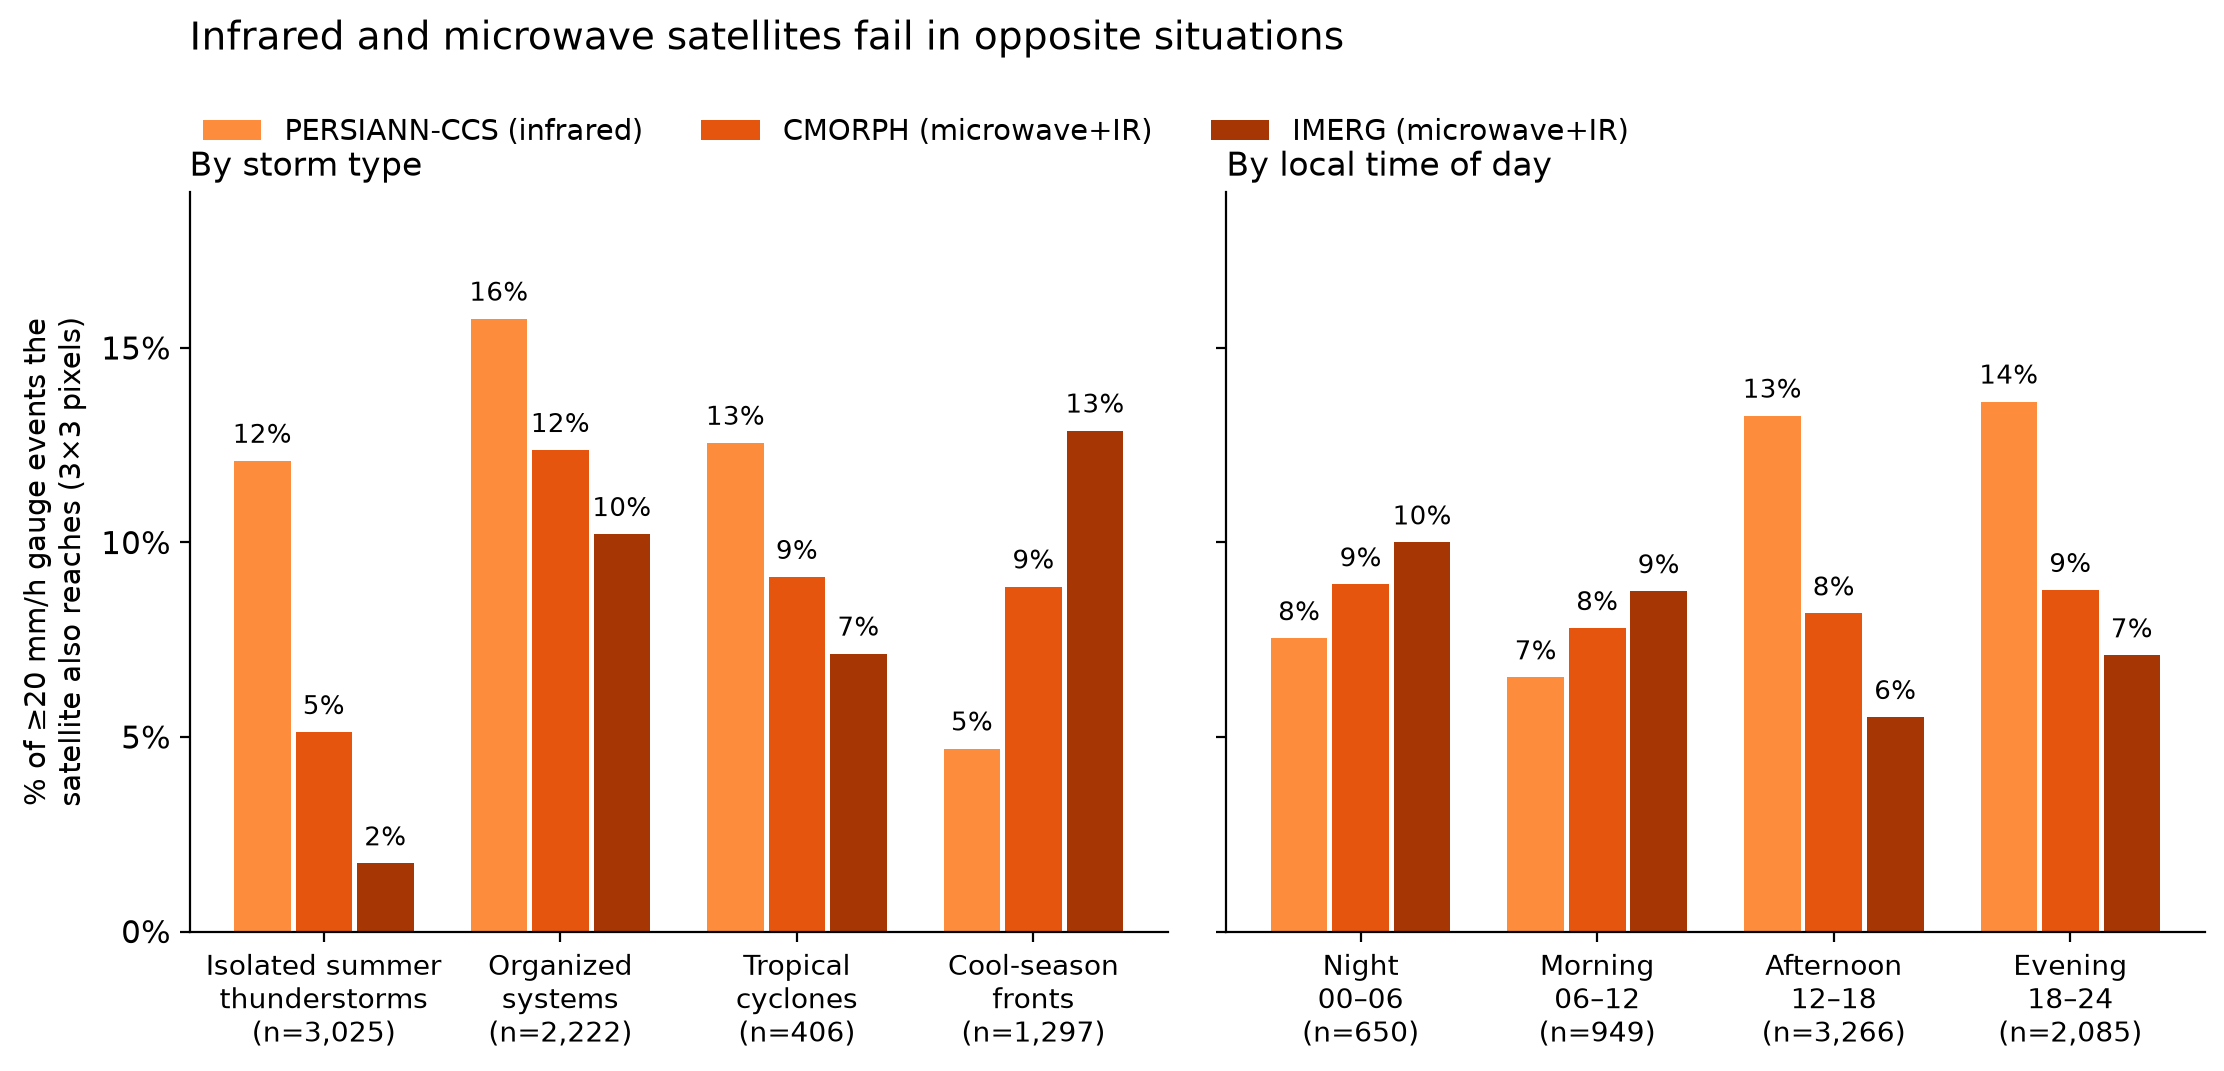

In [191]:
# [orig cell 190 | env: python | status: ok]
axs[0].get_legend().remove()
hh,ll=axs[0].get_legend_handles_labels()
fig.legend(hh,ll,frameon=False,fontsize=10.5,ncol=3,loc='upper left',bbox_to_anchor=(0.12,0.985))
fig._suptitle.set_y(1.06)
axs[0].set_yticks([0,5,10,15]); axs[0].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(100,decimals=0))
fig.savefig('sat_fig3_conditions.png',dpi=200,bbox_inches='tight')
r=fig.canvas.get_renderer(); tx=[x_ for x_ in fig.findobj(mpl.text.Text) if x_.get_text().strip() and x_.get_visible()]; bb=[x_.get_window_extent(r) for x_ in tx]
print([(tx[i].get_text()[:18],tx[j].get_text()[:18]) for i in range(len(bb)) for j in range(i+1,len(bb)) if bb[i].overlaps(bb[j])])

In [199]:
# [orig cell 198 | env: python | status: ok]
A=lambda v:'{{!artifact:'+v+'}}'
t30=DS[DS.threshold==30].set_index(['product','nbhd'])
chk={p:(round(t30.loc[(p,'N9'),'hit_ge1']*100),round(t30.loc[(p,'N9'),'hit_ge10']*100),round(t30.loc[(p,'N9'),'hit_strict']*100,1),round(t30.loc[(p,'N16'),'hit_strict']*100,1),round(t30.loc[(p,'N1'),'ratio_median']*100),round(t30.loc[(p,'N16'),'ratio_median']*100)) for p in ['pccs','cmorph','imerg','stage4']}
print(chk)
art=f"""# Satellites see the storm, not the downpour: what I learned testing satellite rainfall against Florida's heaviest hours

At 6 pm on 26 May 2020, the rain gauge at Miami International Airport measured **84.6 mm of rain in one hour**, enough to flood streets within minutes.

Three widely used satellite rainfall products were watching the same hour from orbit. Over the gauge they showed **8 mm, 11 mm and 5 mm**. Ground-based radar showed 55 mm.

![What radar and three satellite products showed over the Miami gauge]({A('9af1e37b-b1d1-4ee6-8d31-7ff9a0abc266')})

Satellite rainfall is one of the great achievements of Earth observation. It covers the whole globe every 30 minutes, including oceans, mountains and countries with almost no rain gauges. It feeds flood forecasting, drought monitoring, climate research and hazard maps around the world. So the question matters: **when it really pours, how much of it do satellites capture?**

## What I tested
* **Ground truth:** 79 quality-controlled hourly rain gauges across Florida (NOAA's GHCNh), 2015–2025.
* **Extremes:** every hour with at least 20, 30, 40 or 50 mm of rain at a gauge. That is thousands of events, from sea-breeze thunderstorms to hurricanes.
* **Satellite products:**
  * **IMERG V07 Final** (NASA, about 10 km pixels): combines microwave and infrared satellites, with monthly gauge adjustment.
  * **CMORPH CDR** (NOAA, 8 km): microwave and infrared, bias-corrected.
  * **PERSIANN-CCS** (UC Irvine, 4 km): infrared cloud-top temperatures only.
* **Yardstick:** NOAA's Stage IV radar analysis.
* **The test:** for each extreme hour, did the product show the same intensity? I checked the pixel over the gauge and blocks of 2×2, 3×3 and 4×4 pixels around it, so that small position errors weren't penalised.

## What I found

![Satellites see the storm but rarely the downpour]({A('e6a3f551-65d1-414d-8e63-90aacf8d7af7')})

**1. Satellites almost always see the storm.** For hours with at least 30 mm of rain, the satellite products show *some* rain near the gauge in **82–94%** of cases. Detection and location are not the problem.

**2. They rarely see the downpour.**
* Only **34–41%** of those events show even heavy rain (≥10 mm/h).
* Just **2–6%** reach the gauge's intensity of ≥30 mm/h, against **66%** for radar.
* Over the gauge, the satellites typically show about **10% of the peak** the gauge measured. Radar shows about 62%.

**3. Looking wider doesn't fix it.** Even taking the maximum over a 4×4-pixel box (16–40 km across), satellites reach the extreme in only **3–8%** of events and show about **20%** of the peak. The storm's core is not merely displaced; it is smoothed away.

![Infrared and microwave satellites fail in opposite situations]({A('c36b18be-3231-4b57-a4f5-b9086895ecdd')})

**4. Different satellite types fail in opposite situations.**
* **Isolated summer thunderstorms,** Florida's most common extreme:
  * PERSIANN-CCS (infrared) reaches the threshold in **12%** of events; IMERG in only **2%**.
  * Infrared sees the very cold tops of deep afternoon thunderstorms. Microwave sensors measure rain more directly but pass over only every few hours, so short-lived storms can slip between overpasses.
* **Cool-season frontal rain:** the order flips. IMERG reaches **13%**, PERSIANN-CCS **5%**. Widespread, longer-lasting rain from shallower clouds suits microwave sensing and fools cloud-top temperature methods.
* **Time of day:** the same split. Infrared does best in the afternoon and evening; microwave-based products do relatively best at night and in the morning.

**5. Finer pixels help, but not enough.** PERSIANN-CCS has the smallest pixels (4 km) and the highest hit rate among the satellites. IMERG has the coarsest (10 km) but most often places rain near the gauge (94%). Neither comes close to radar on intensity.

## What this means
* **Use satellites for where and when it rains, not how hard.** They are excellent at detecting storms and mapping coverage, and weak at hourly peak intensity.
* **Infrastructure and flood design:** design rainfall (IDF curves) or flood models built on raw satellite data would understate the storms that matter most.
* **Data-poor regions:** many countries rely on satellites alone for rainfall hazard. Florida, with its dense radar and gauge networks, suggests those estimates of extremes may be far too low.
* **Pick the product for the weather regime:** infrared-based for summer convection, microwave-based for frontal and cool-season rain. Better still, blend them.
* **Bias correction should depend on storm type,** because a single correction factor can't fix errors that change sign between regimes.

## Caveats
* A gauge measures a point and a satellite pixel averages tens to hundreds of square kilometres, so some smoothing is expected. The point is that satellite products are often used for exactly these point-scale, hourly questions.
* This is one state and one decade.
* Storm types were classified with simple proxies.
* The radar yardstick is itself partly gauge-adjusted.

## What's next
I'm interested in **storm-type-aware correction of satellite rainfall**, and in using high-resolution radar to translate pixel averages into the point intensities engineers design for.

If you work with satellite precipitation, which product do you trust for extremes, and in which weather? I'd love to hear from the remote-sensing, hydrology and engineering communities.

#RemoteSensing #SatellitePrecipitation #IMERG #ExtremeRainfall #Hydrology #FloodRisk #EarthObservation #ClimateResilience #Florida
"""
open('linkedin_article_satellites.md','w').write(art); print(len(art.split()))

{'pccs': (82, 41, np.float64(6.4), np.float64(8.1), 10, 23), 'cmorph': (83, 35, np.float64(3.0), np.float64(4.1), 9, 19), 'imerg': (94, 34, np.float64(2.2), np.float64(2.9), 10, 21), 'stage4': (98, 93, np.float64(66.3), np.float64(69.7), 62, 97)}
840


In [215]:
# [orig cell 214 | env: python | status: ok]
g=DS.set_index(['product','threshold','nbhd'])
for p in ['pccs','cmorph','imerg','stage4','mrms_radaronly','mrms_gaugecorr']:
    print(p, '≥20 N9 strict',round(g.loc[(p,20,'N9'),'hit_strict']*100,1), '| ≥30 N9 strict',round(g.loc[(p,30,'N9'),'hit_strict']*100,1),
          '| ≥30 N1 ratio',round(g.loc[(p,30,'N1'),'ratio_median']*100), '| ≥30 N9 no-rain',round((1-g.loc[(p,30,'N9'),'hit_ge1'])*100),'| n20',int(g.loc[(p,20,'N9'),'n_events']))
c20=CS[(CS.threshold==20)&(CS.nbhd=='N9')&(CS.condition=='storm_type')]
print(c20[c20['product'].isin(['pccs','imerg','cmorph'])].pivot_table(index='level',columns='product',values='hit_strict').round(3))
# Gauge-network split for radar-only vs stage4 (ASOS gauges could feed Stage IV)
gn=CS[(CS.threshold==30)&(CS.nbhd=='N9')&(CS.condition=='gauge_network')]
print(gn[gn['product'].isin(['stage4','mrms_radaronly'])][['product','level','hit_strict','ratio_median','n_events']])

pccs ≥20 N9 strict 11.9 | ≥30 N9 strict 6.4 | ≥30 N1 ratio 10 | ≥30 N9 no-rain 18 | n20 6950
cmorph ≥20 N9 strict 8.4 | ≥30 N9 strict 3.0 | ≥30 N1 ratio 9 | ≥30 N9 no-rain 17 | n20 6950
imerg ≥20 N9 strict 6.8 | ≥30 N9 strict 2.2 | ≥30 N1 ratio 10 | ≥30 N9 no-rain 6 | n20 6950
stage4 ≥20 N9 strict 73.9 | ≥30 N9 strict 66.3 | ≥30 N1 ratio 62 | ≥30 N9 no-rain 2 | n20 6950
mrms_radaronly ≥20 N9 strict 64.9 | ≥30 N9 strict 53.3 | ≥30 N1 ratio 63 | ≥30 N9 no-rain 2 | n20 6950
mrms_gaugecorr ≥20 N9 strict 66.2 | ≥30 N9 strict 54.6 | ≥30 N1 ratio 71 | ≥30 N9 no-rain 2 | n20 6950
product                           cmorph  imerg   pccs
level                                                 
Cool-season (frontal)              0.089  0.129  0.047
Tropical cyclone                   0.091  0.071  0.126
Warm-season isolated convection    0.051  0.018  0.121
Warm-season organized (MCS-like)   0.124  0.102  0.158
            product           level  hit_strict  ratio_median  n_events
779  mrms_radaronly

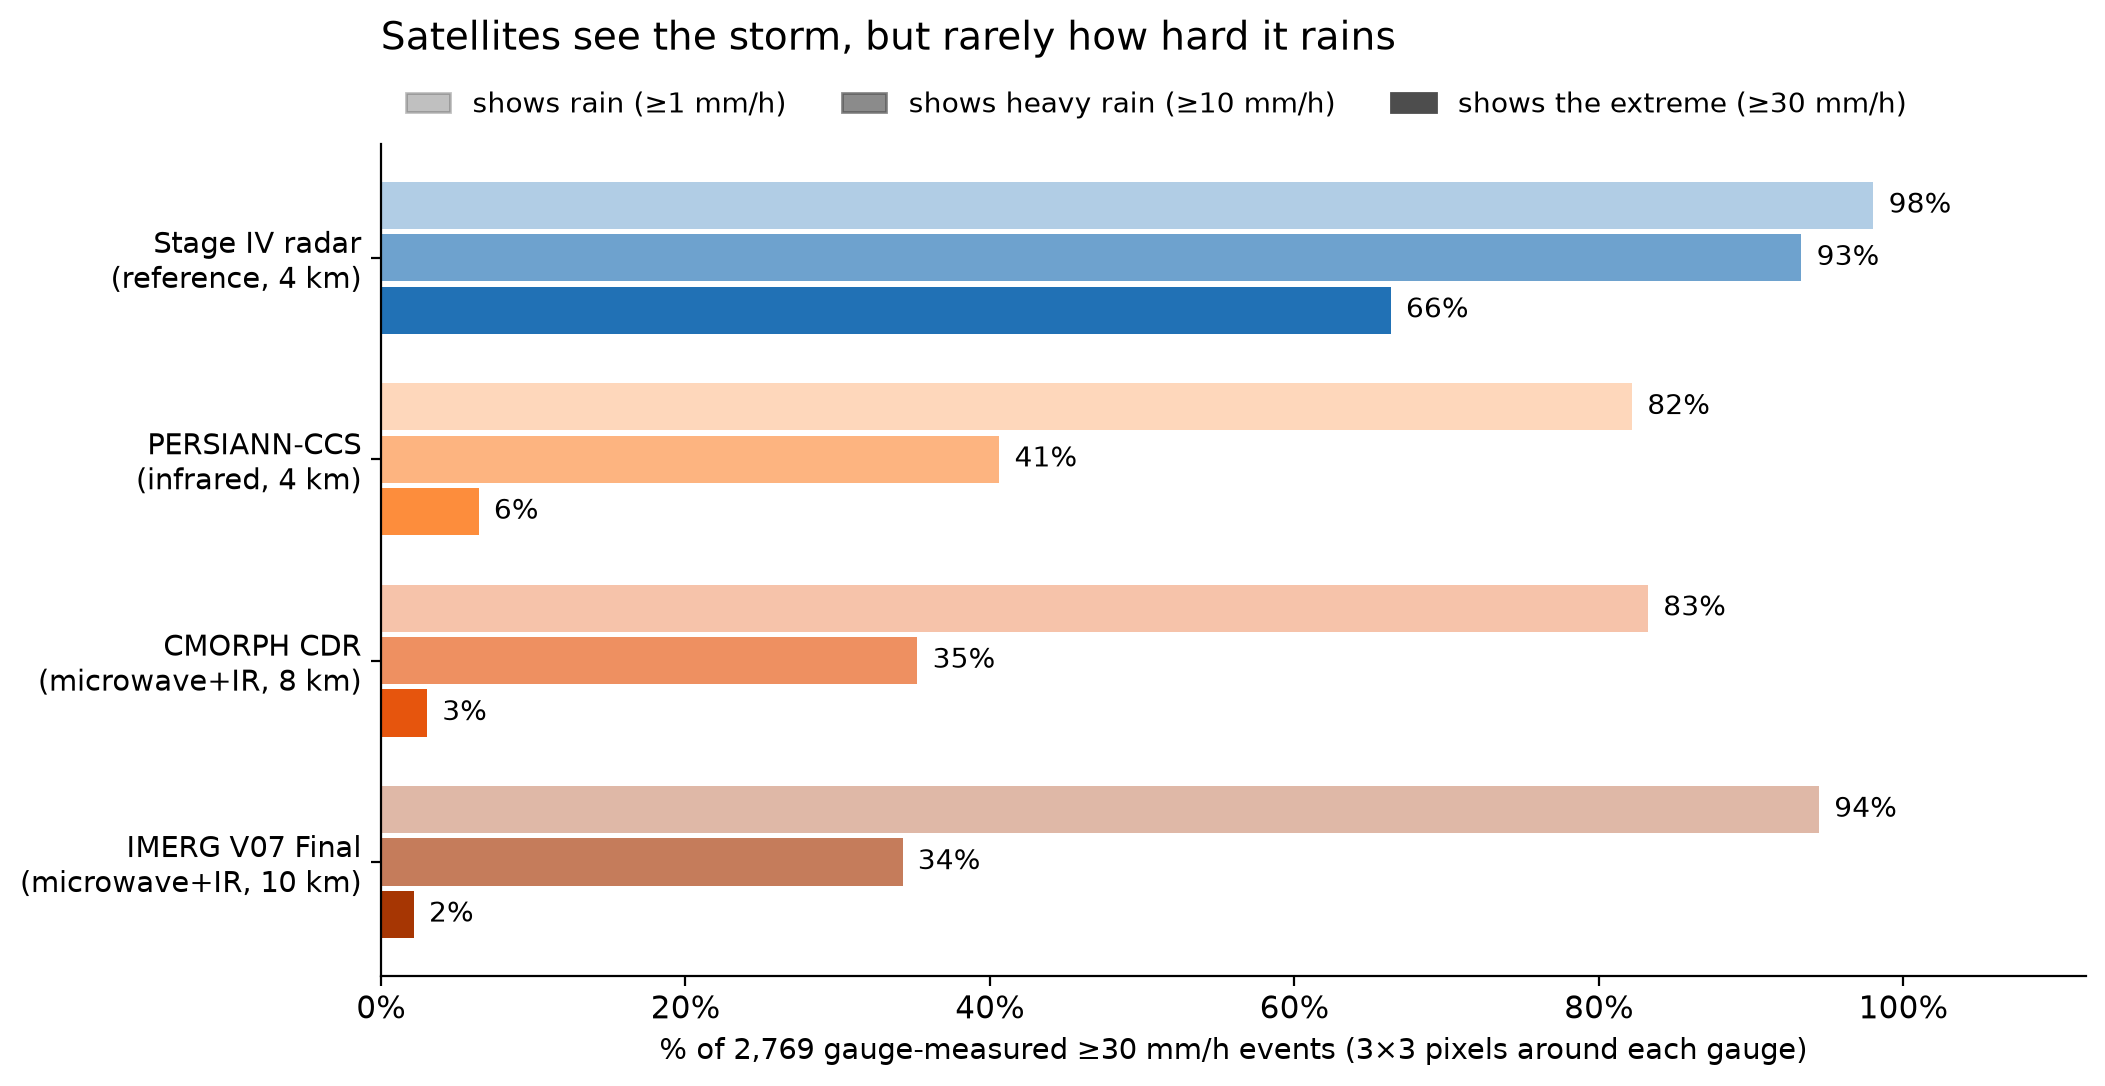

In [221]:
# [orig cell 220 | env: python | status: ok]
import pandas as pd, numpy as np, matplotlib as mpl, matplotlib.pyplot as plt, matplotlib.patches as mpa
mpl.rcParams.update({'font.size':11,'font.family':'DejaVu Sans','axes.spines.top':False,'axes.spines.right':False})
DS=pd.read_csv('out/detection_scores.csv')
nice={'stage4':'Stage IV radar\n(reference, 4 km)','pccs':'PERSIANN-CCS\n(infrared, 4 km)','cmorph':'CMORPH CDR\n(microwave+IR, 8 km)','imerg':'IMERG V07 Final\n(microwave+IR, 10 km)'}
col={'stage4':'#2171b5','pccs':'#fd8d3c','cmorph':'#e6550d','imerg':'#a63603'}
order=['imerg','cmorph','pccs','stage4']; t=DS[(DS.threshold==30)&(DS.nbhd=='N9')].set_index('product')
steps=[('hit_ge1','shows rain (≥1 mm/h)'),('hit_ge10','shows heavy rain (≥10 mm/h)'),('hit_strict','shows the extreme (≥30 mm/h)')]; shades=[0.35,0.65,1.0]
y=np.arange(4)*1.0; h=0.26
fig,ax=plt.subplots(figsize=(11,5.4))
for k,(c_,lab) in enumerate(steps):
    for i,p in enumerate(order):
        v=t.loc[p,c_]*100; yy=y[i]+(1-k)*h
        ax.barh(yy,v,h*0.9,color=col[p],alpha=shades[k]); ax.text(v+1,yy,f'{v:.0f}%',va='center',fontsize=10)
ax.set_yticks(y); ax.set_yticklabels([nice[p] for p in order],fontsize=10.5)
ax.set_xlim(0,112); ax.set_xticks([0,20,40,60,80,100]); ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(100))
ax.set_xlabel('% of 2,769 gauge-measured ≥30 mm/h events (3×3 pixels around each gauge)',fontsize=10.5)
ax.legend(handles=[mpa.Patch(color='0.3',alpha=a,label=l) for a,(_,l) in zip(shades,steps)],frameon=False,fontsize=10,loc='lower left',bbox_to_anchor=(0,1.0),ncol=3,handlelength=1.6)
ax.set_title('Satellites see the storm, but rarely how hard it rains',loc='left',fontsize=14,pad=34)
fig.savefig('sat_fig2_funnel.png',dpi=200,bbox_inches='tight')

In [222]:
# [orig cell 221 | env: precip | status: ok]
for t_ in fig.texts:
    if t_.get_text().startswith('Satellites see'): t_.set_text("Satellites miss 9 in 10 of Florida's heaviest rains"); t_.set_fontsize(48)
fig.savefig('cover_linkedin_1920x1080.png',dpi=100,facecolor=bg)
r=fig.canvas.get_renderer(); bb=[t_.get_window_extent(r) for t_ in fig.texts if 'heaviest' in t_.get_text()][0]; print('title px span',round(bb.x0),round(bb.x1))

title px span 42 1878


133 1787


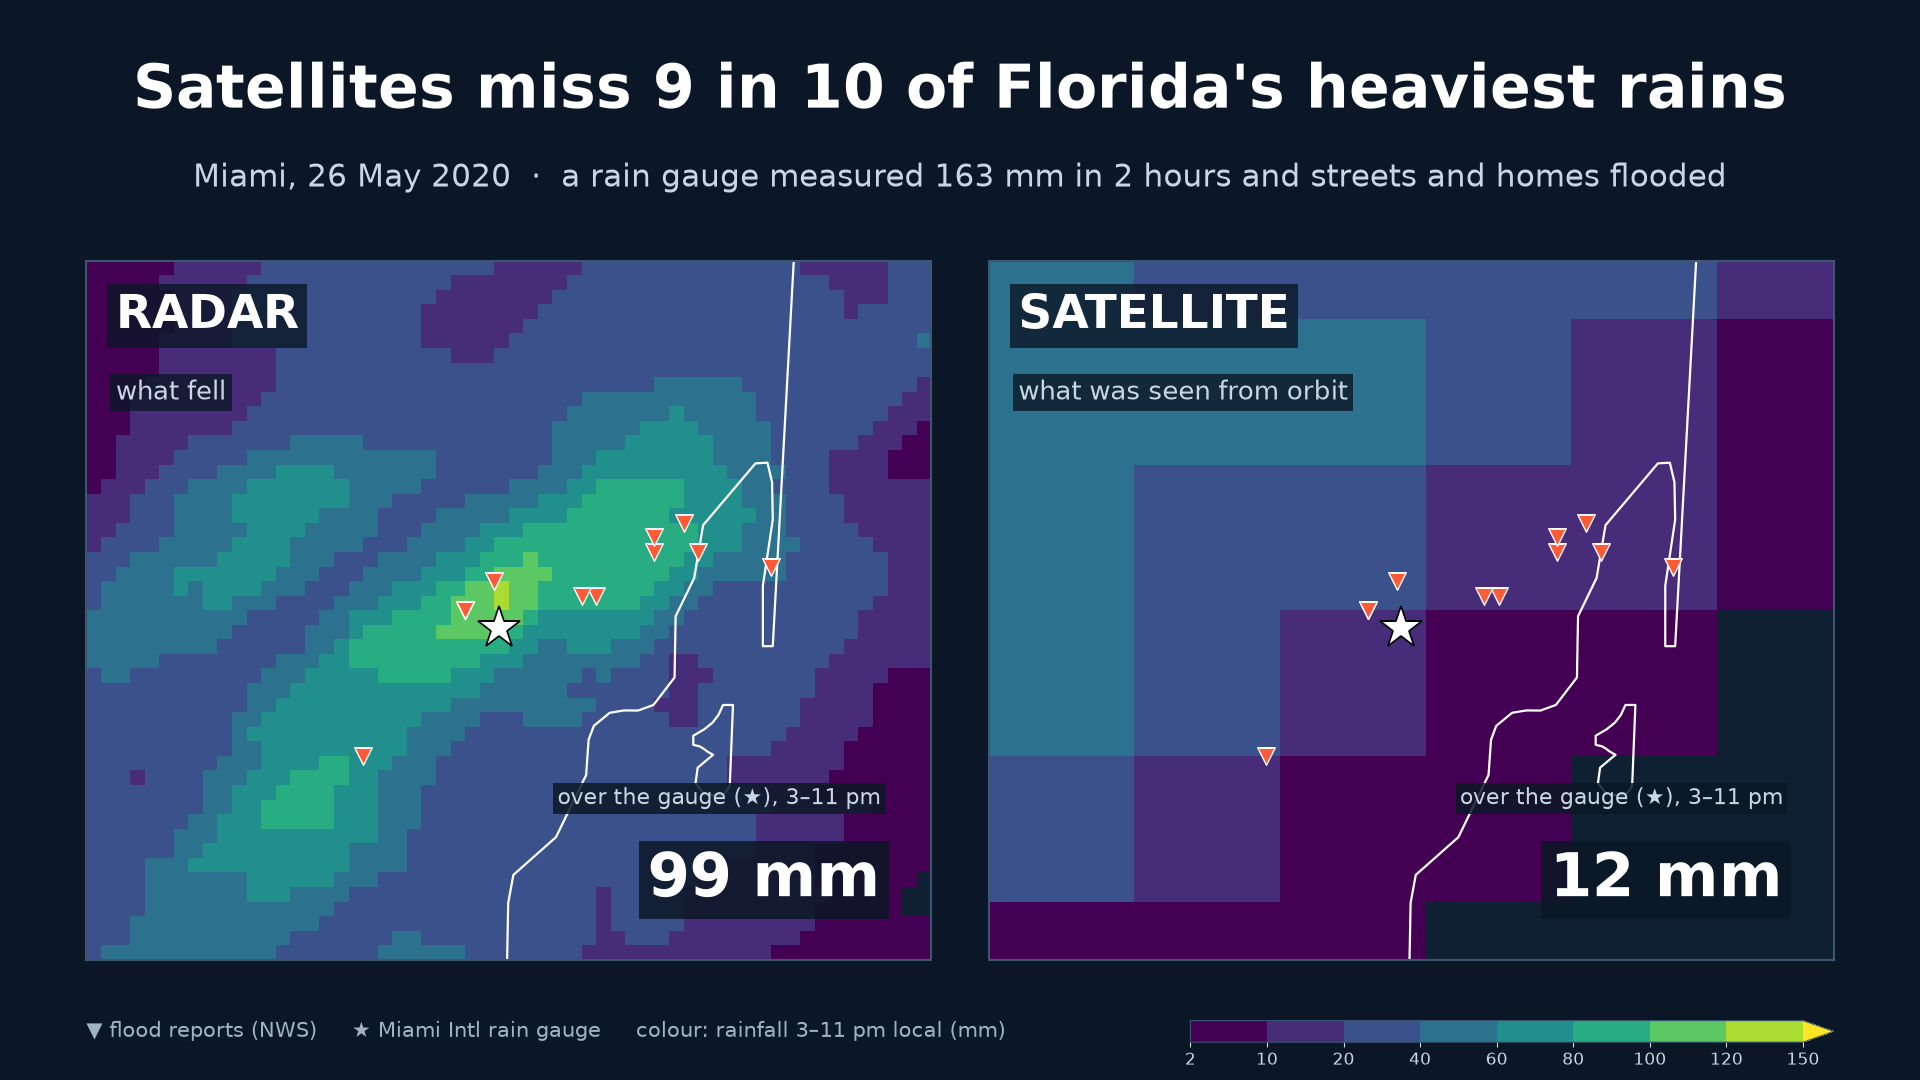

In [223]:
# [orig cell 222 | env: precip | status: ok]
for t_ in fig.texts:
    if 'heaviest' in t_.get_text(): t_.set_fontsize(43)
fig.savefig('cover_linkedin_1920x1080.png',dpi=100,facecolor=bg)
r=fig.canvas.get_renderer(); bb=[t_.get_window_extent(r) for t_ in fig.texts if 'heaviest' in t_.get_text()][0]; print(round(bb.x0),round(bb.x1))